# The CNN object tour: what the robot's camera saw

Extra demo world `webots_project/worlds/cnn_objects.wbt` (not part of the main results). The e-puck **finds the objects itself** with a 360° lidar, drives to each one and decides what it is:

- a view filled by one coloured blob is a **coloured block** (HSV detector),
- anything else is photographed three times (normal distance, 15% closer, 15% further) and named by the **int8 CIFAR-10 CNN**; the views vote, and if fewer than two agree or the mean confidence is under 60% the robot says **"unsure"**.

The paper boat stands on a sea-coloured patch, to test whether water makes the CNN say "ship".

The photos from one run are in `webots_object_tour/`, named `<n>_object<k>_view<v>.png`, where *k* is the order in which the lidar found the objects. This notebook re-runs the robot's int8 CNN on those photos with the robot's own crop and resize, so the answers match what the robot printed (up to small rounding differences). What each object really is comes from the world file and is used only for scoring.

In [1]:
import pathlib, re
from collections import defaultdict
import numpy as np, cv2 as cv, matplotlib.pyplot as plt

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
# Lidar object number -> what it really is (from the world file; used only for scoring).
TRUTH = {1: "truck", 2: "green block", 3: "horse", 4: "blue block", 5: "car", 6: "paper boat", 7: "deer", 8: "red block"}
EXPECTED = {"truck": "truck", "horse": "horse", "car": "automobile", "paper boat": "ship", "deer": "deer"}
IMAGES = pathlib.Path("webots_object_tour")
MODEL = pathlib.Path("results/models/cifar10_cnn_int8.tflite")

try:  # the robot's runtime; Colab has TensorFlow instead
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    import tensorflow as tf
    Interpreter = tf.lite.Interpreter
interp = Interpreter(model_path=str(MODEL)); interp.allocate_tensors()
inp, out = interp.get_input_details()[0], interp.get_output_details()[0]

def centre_square(bgr):
    h, w = bgr.shape[:2]; s = min(h, w); y, x = (h - s) // 2, (w - s) // 2
    return bgr[y:y + s, x:x + s]

def predict(bgr):
    rgb = cv.cvtColor(centre_square(bgr), cv.COLOR_BGR2RGB)
    x = (cv.resize(rgb, (32, 32), interpolation=cv.INTER_AREA).astype(np.float32) / 255.0)[None]
    scale, zero = inp["quantization"]
    interp.set_tensor(inp["index"], np.round(x / scale + zero).clip(-128, 127).astype(inp["dtype"]))
    interp.invoke()
    q = interp.get_tensor(out["index"])[0].astype(np.float32)
    s, z = out["quantization"]; logits = (q - z) * s
    p = np.exp(logits - logits.max()); return p / p.sum()

def vote(answers, min_views=2, min_mean=0.6):  # same rule as the robot (lidar_objects.vote)
    totals, wins = defaultdict(float), defaultdict(int)
    for label, conf in answers: totals[label] += conf; wins[label] += 1
    best = max(totals, key=totals.get); mean = totals[best] / len(answers)
    return best, mean, wins[best] >= min_views and mean >= min_mean

rows = defaultdict(list)
for f in sorted(IMAGES.glob("*.png")):
    k, v = map(int, re.match(r"\d+_object(\d+)_view(\d)", f.stem).groups())
    if "block" in TRUTH[k]: continue
    p = predict(cv.imread(str(f))); c = int(p.argmax())
    rows[k].append((v, CLASS_NAMES[c], float(p[c]), f))
assert len(rows) == 5 and all(len(r) == 3 for r in rows.values()), "expected 5 objects x 3 views"
for k, r in rows.items():
    label, mean, sure = vote([(l, c) for _, l, c, _ in r])
    said = f"{label} ({mean:.0%})" if sure else f"unsure ({label}? {mean:.0%})"
    print(f"object {k} ({TRUTH[k]:10s}): " + ", ".join(f"view {v}: {l} {c:.0%}" for v, l, c, _ in r) + f"  ->  {said}")

object 1 (truck     ): view 1: truck 38%, view 2: truck 85%, view 3: truck 61%  ->  truck (61%)
object 3 (horse     ): view 1: horse 98%, view 2: deer 95%, view 3: horse 100%  ->  horse (66%)
object 5 (car       ): view 1: automobile 99%, view 2: automobile 100%, view 3: automobile 50%  ->  automobile (83%)
object 6 (paper boat): view 1: airplane 89%, view 2: airplane 94%, view 3: airplane 99%  ->  airplane (94%)
object 7 (deer      ): view 1: deer 100%, view 2: deer 100%, view 3: deer 100%  ->  deer (100%)


## Every photo, and the verdict after the vote

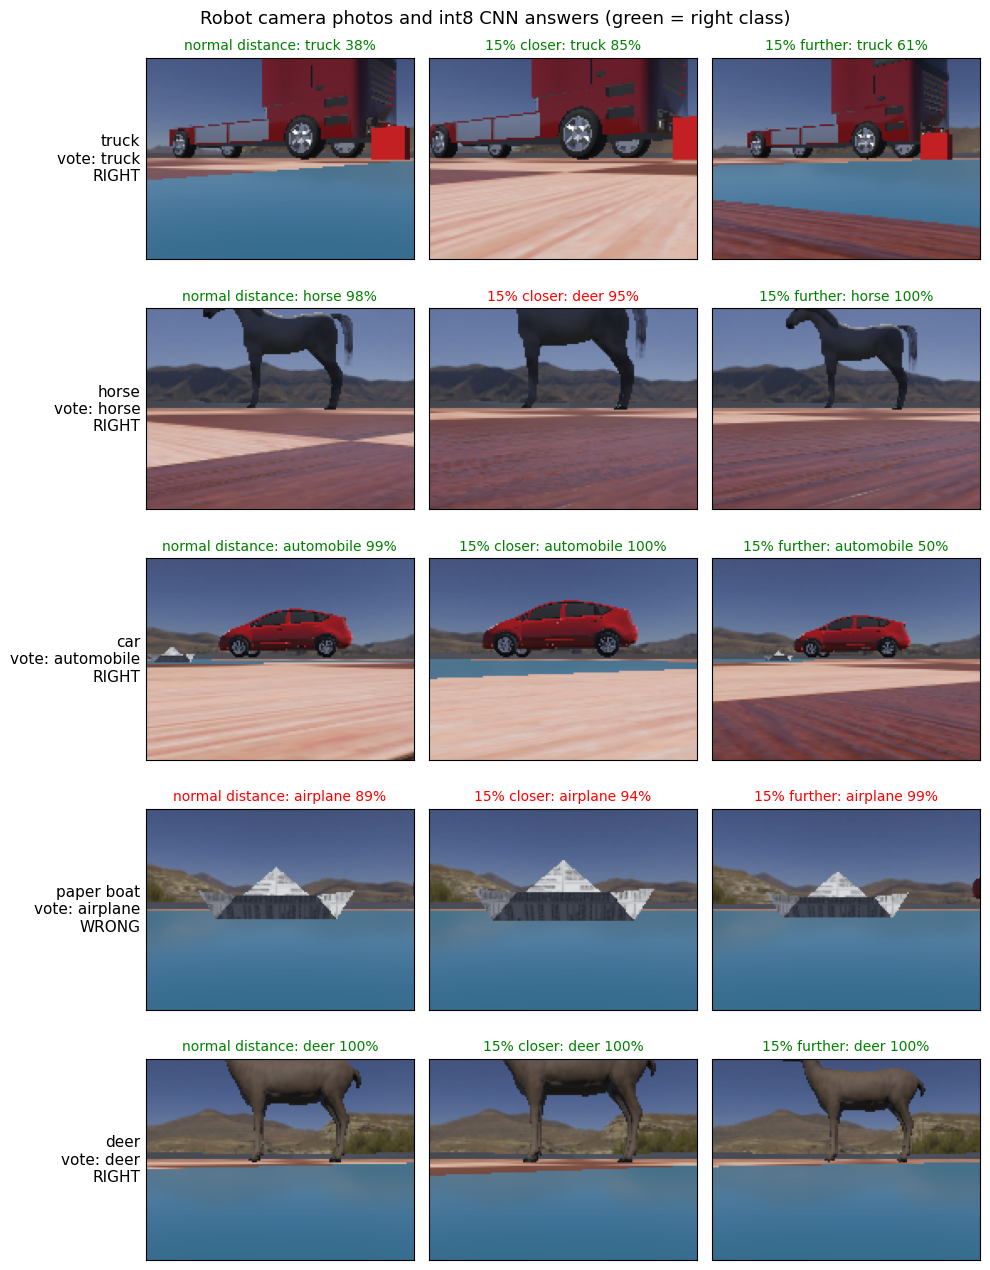

In [2]:
fig, axes = plt.subplots(len(rows), 3, figsize=(10, 13))
names = {1: "normal distance", 2: "15% closer", 3: "15% further"}
for r_i, (k, r) in enumerate(rows.items()):
    for v, label, conf, f in r:
        ax = axes[r_i, v - 1]; ax.imshow(cv.cvtColor(cv.imread(str(f)), cv.COLOR_BGR2RGB)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{names[v]}: {label} {conf:.0%}", color="green" if label == EXPECTED[TRUTH[k]] else "red", fontsize=10)
    best, mean, sure = vote([(l, c) for _, l, c, _ in r])
    ok = sure and best == EXPECTED[TRUTH[k]]
    axes[r_i, 0].set_ylabel(f"{TRUTH[k]}\nvote: {best if sure else 'unsure'}\n{'RIGHT' if ok else 'WRONG'}", fontsize=11, rotation=0, ha="right", va="center")
fig.suptitle("Robot camera photos and int8 CNN answers (green = right class)", fontsize=13)
fig.tight_layout(); plt.show()

## What this shows

- With the lidar finding the objects by itself, the robot found **all 8** (none missed, no false detections) and named **7 of 8 correctly**: the three blocks by colour, and the truck, horse, car and deer by the CNN after the vote.
- **The paper boat is still called "airplane"** (92–99%), even standing on water that reaches the horizon. So it is not just the missing water: the boat's shape, two pointed white tips against the sky, is what the CNN reads as an airplane (see the Grad-CAM in `gradcam_tour_bird.ipynb`).
- The vote matters: the horse's middle photo says "deer" at 95%, and only the other two views make the verdict right. In some runs the truck came out **"unsure"** instead of wrong, which is the behaviour the 60% rule is for.
- The three coloured blocks were named by the HSV detector, not the CNN, so they are not in this figure.